![Banner](../../../Images/Banner/09_distributed_spatial_datas.png)

# Reading and Writing Big Spatial Data in Parallel

Most large spatial workflows spend more time reading and writing than computing. A slope
calculation on the Great Plains DEM takes a fifth of a second on a GPU, but decoding the DEM from
disk takes longer, and a 15 GB Cropland Data Layer cannot even be held in memory. How data are
**laid out on disk** decides whether many workers can read them at once, whether a small window
can be read without touching the rest, and whether a reader can skip files that lie outside the
area of interest. This notebook reads and writes rasters (GeoTIFF, Cloud-Optimized GeoTIFF, Zarr,
STAC catalogues) and vectors (GeoParquet, Shapefile, GeoPackage, partitioned datasets) with
`geolattice.distributed.io`, and measures how layout and chunking change the speed.

## Overview

### Raster layouts

| Format | Layout | Good for | Watch out for |
|---|---|---|---|
| GeoTIFF, **striped** | rows stored one after another | reading whole rows or the whole file | a small window still reads full rows |
| GeoTIFF, **tiled** | square blocks (here 128 x 128) stored independently | windows, parallel reads of blocks | chunks should be multiples of the block size |
| **Cloud-Optimized GeoTIFF (COG)** | tiled, plus internal overviews, with the header first | HTTP range requests from object storage, quick previews | written once; updating is awkward |
| **Zarr** | one compressed file (object) per chunk, plus JSON metadata | parallel reads and writes, cloud storage, n-dimensional cubes | many small objects if chunks are tiny |

A Dask chunk that covers parts of several file blocks forces each task to read and decode blocks
that other tasks also read. **Chunks aligned to the storage blocks** (equal to them or a whole
multiple) avoid the duplicate work.

### Vector layouts

| Format | Parallel read | Spatial filter without reading everything |
|---|---|---|
| Shapefile, GeoPackage, FlatGeobuf (OGR) | by row ranges (each worker skips to its rows) | spatial index inside the file (GeoPackage, FlatGeobuf) |
| **GeoParquet** | one task per file or row group | per-file and per-row-group bounding box statistics (the `bbox` covering column, GeoParquet 1.1) |
| **Partitioned GeoParquet** | one task per file, files written in parallel | whole files skipped when their bounding box misses the query |

Columnar storage also lets a reader take only the columns it needs. And when rows are written in
**Hilbert order**, each file covers a compact area, so a bounding-box query touches few files.

### STAC

A SpatioTemporal Asset Catalog lists satellite scenes and the URLs of their COG bands. A lazy
reader (here `odc-stac`) turns a search result into an `xarray` cube whose chunks are read only
when computed, directly from object storage.

## Input and Output with GeoLattice

| Function | Reads or writes | Parallelism |
|---|---|---|
| `pdist.read_raster(path, chunks=)` | any GDAL raster, lazily | one task per chunk; `chunks="auto"` uses `plan_chunks`; `compute="gpu"` gives CuPy chunks |
| `pdist.write_raster(obj, path, format=)` | `"zarr"`, `"gtiff"`, `"cog"` | Zarr chunks written in parallel; GeoTIFF chunk by chunk under a lock |
| `pdist.read_zarr(store)` | Zarr store, lazily | the store's chunks |
| `pdist.read_stac(items, bands=, resolution=, bbox=)` | STAC items through `odc.stac.load` | 2048 x 2048 chunks by default |
| `pdist.read_vector(path, npartitions=, bbox=, columns=, lazy=)` | GeoParquet file, folder or glob; OGR files | one task per Parquet file, or `npartitions` row ranges of an OGR file; `lazy=True` returns dask-geopandas |
| `pdist.write_vector(gdf, path, npartitions=, partition_on=)` | partitioned GeoParquet | Hilbert-sorted partitions written in parallel, with a `bbox` covering column |
| `pdist.spatial_partition`, `pdist.partition_bounds` | (helpers) | Hilbert order and per-partition bounding boxes |

### Learning objectives

1. Explain striped, tiled, COG and Zarr layouts, and GeoParquet row groups and partitions.
2. Read rasters lazily with chunks aligned to the file's blocks, and measure the effect of
   misaligned chunks.
3. Read a small window of the 152 billion pixel CDL without reading the rest.
4. Write rasters to Zarr and COG, and compare read speed and size with the original GeoTIFF.
5. Load a lazy Sentinel-2 cube from a STAC catalogue.
6. Read and write partitioned GeoParquet, filter by bounding box, and compare GeoParquet with
   Shapefile and GeoPackage.
7. Treat 38 million taxi trips as a lazy Dask DataFrame.

### Data

| Dataset | Content |
|---|---|
| Great Plains covariates | 15 rasters, 17,196 x 15,245, float32, tiled 128 x 128, uncompressed, 1.06 GB each |
| 2025 CONUS CDL | 316,295 x 480,509 pixels at 10 m (152 billion), uint8, 576 x 512 tiles, PackBits, 15 GB |
| Kansas building footprints | 1.6 million polygons, 24 Hilbert-sorted GeoParquet files (notebook 00) |
| Sentinel-2 L2A | Planetary Computer STAC, Wichita, summer 2025 |
| NYC yellow taxi trips 2023 | one Parquet file, 38.3 million rows in 37 row groups |

Files written here go to `outputs/io/` and are deleted at the end (about 6 GB at the peak).
Timings depend on whether files are already in the operating system's page cache: the first read
of a file comes from disk, repeated reads from memory. The comparisons below read every file once
before timing, so they compare decoding and layout, not the disk.

### Contents

- Setup
- Lazy rasters and block-aligned chunks
- A window of the 152 billion pixel CDL
- GeoTIFF, COG and Zarr compared
- A multi-layer Zarr cube
- A lazy Sentinel-2 cube from STAC
- Partitioned GeoParquet
- GeoParquet, Shapefile and GeoPackage
- 38 million taxi trips as a lazy table
- Summary and exercises

## Setup

In [1]:
import warnings  # warning control
warnings.filterwarnings("ignore")  # hide routine library warnings
import os  # environment and CPU count
import time  # wall-clock timing
from pathlib import Path  # file paths

import matplotlib.pyplot as plt  # figures
import numpy as np  # arrays
import pandas as pd  # tables
import geopandas as gpd  # vector data
import xarray as xr  # labelled rasters

import geolattice  # GeoLattice
import geolattice.distributed as pdist  # distributed and GPU spatial computing
import dist_data as dd  # chapter helper: paths, cached downloads, timers

plt.rcParams.update({"figure.dpi": 110})  # figure resolution
pd.set_option("display.width", 140)  # wider printed tables
OUT = Path("outputs")  # results and scratch files written by this chapter
OUT.mkdir(exist_ok=True)  # create it if needed
caps = pdist.capabilities()  # engines and GPUs on this machine
print("GeoLattice", geolattice.__version__, "|", os.cpu_count(), "CPU cores |", caps["gpus"], "GPU(s)",  # versions
      f"({caps.get('gpu_memory_total', 0) / 1e9:.0f} GB)" if caps["gpus"] else "")  # GPU memory

import shutil  # remove scratch files
import subprocess  # gdal_translate for a striped copy
import dask  # Dask configuration
IO = OUT / "io"  # scratch folder for this notebook
IO.mkdir(parents=True, exist_ok=True)  # create it


def folder_gb(p):  # size of a file or folder on disk
    p = Path(p)  # as a path
    return sum(f.stat().st_size for f in p.rglob("*") if f.is_file()) / 1e9 if p.is_dir() else p.stat().st_size / 1e9  # bytes to GB

GeoLattice 0.3.49 | 24 CPU cores | 1 GPU(s) (17 GB)


## Lazy rasters and block-aligned chunks

The Great Plains GeoTIFFs store 128 x 128 pixel blocks. `pdist.read_raster` with
`chunks="auto"` asks `pdist.plan_chunks` for about 128 MB chunks; explicit chunks of 2048 are a
multiple of the block, and 2000 are not.

In [2]:
src = dd.GP_RASTERS / "elev.tif"  # the DEM
auto = pdist.read_raster(src)  # chunks="auto"
print("auto chunks:", auto.data.chunksize, "|", auto.data.npartitions, "chunks | lazy:", pdist.is_lazy(auto))  # plan
rows = []  # timings
cases = [("DEM, uncompressed, 128 x 128 blocks", src, None, [((2048, 2048), True), ((2000, 2000), False)]),  # file, window, chunkings
         ("CDL, PackBits, 512 x 576 blocks", dd.CDL, (slice(128000, 160768), slice(144000, 180864)),
          [((4096, 4608), True), ((4000, 4500), False)])]
for name, path, window, chunkings in cases:  # both files
    for ch, aligned in chunkings:  # aligned first, then misaligned
        r = pdist.read_raster(path, masked=window is None, chunks={"y": ch[0], "x": ch[1]})  # lazy raster
        r = r if window is None else r[window]  # a 33,000 x 37,000 pixel window of the CDL
        float(r.mean())  # warm the page cache
        t = time.perf_counter(); float(r.mean()); sec = time.perf_counter() - t  # read and reduce
        rows.append({"file": name, "chunks": f"{ch[0]} x {ch[1]}", "aligned": aligned,  # description
                     "tasks": r.data.npartitions, "seconds": round(sec, 2)})  # time
pd.DataFrame(rows)  # table

auto chunks: (5632, 5632) | 12 chunks | lazy: True


,file,chunks,aligned,tasks,seconds
0,"DEM, uncompressed, 128 x 128 blocks",2048 x 2048,True,72,0.73
1,"DEM, uncompressed, 128 x 128 blocks",2000 x 2000,False,72,0.70
2,"CDL, PackBits, 512 x 576 blocks",4096 x 4608,True,81,0.57
3,"CDL, PackBits, 512 x 576 blocks",4000 x 4500,False,81,0.57


Alignment made no measurable difference here, for either file (in repeated runs the CDL times
varied by up to a fifth in both directions). With misaligned
chunks the blocks on chunk edges are read by two tasks, but GDAL keeps recently decoded blocks in
its block cache, which all threads of this process share, so the second read is mostly a memory
copy. The penalty
appears where that cache does not help: with several worker **processes** (each has its own
cache, and neighbouring chunks often go to different workers), and with COGs on object storage,
where every misaligned edge block is an extra HTTP range request. Aligning chunks to blocks costs
nothing, so it remains the safe default.

## A window of the 152 billion pixel CDL

The 2025 CDL covers the conterminous United States at 10 m. Opened lazily, it is just a header;
selecting a window by coordinates and computing reads only the blocks inside it.

In [3]:
cdl = dd.cdl()  # lazy uint8 DataArray, 8192 x 8192 chunks
print(f"{cdl.shape[0]:,} x {cdl.shape[1]:,} = {cdl.size / 1e9:.0f} billion pixels, {dd.gb(cdl.nbytes)} as bytes,",  # size
      f"{cdl.data.npartitions:,} chunks, file {dd.gb(dd.CDL.stat().st_size)}")  # on disk
wichita = gpd.GeoSeries.from_xy([-97.34], [37.69], crs=4326).to_crs(5070).iloc[0]  # Wichita, Kansas in EPSG:5070
win = cdl.sel(x=slice(wichita.x - 15000, wichita.x + 15000), y=slice(wichita.y + 15000, wichita.y - 15000))  # 30 x 30 km
with dd.timer("read a 30 x 30 km window (9 million pixels)"):  # only the blocks in the window
    win = win.compute()  # into memory
print(win.shape, f"{win.nbytes / 1e6:.0f} MB", "| process memory", f"{dd.rss_gb():.1f} GB")  # small

316,295 x 480,509 = 152 billion pixels, 151.98 GB as bytes, 2,301 chunks, file 14.92 GB


read a 30 x 30 km window (9 million pixels): 0.18 s
(3000, 3000) 9 MB | process memory 8.5 GB


122 Developed, low       23.4
176 Grass/pasture        19.6
123 Developed, medium    17.0
121 Developed, open       6.8
124 Developed, high       5.7
5 Soybeans                5.1


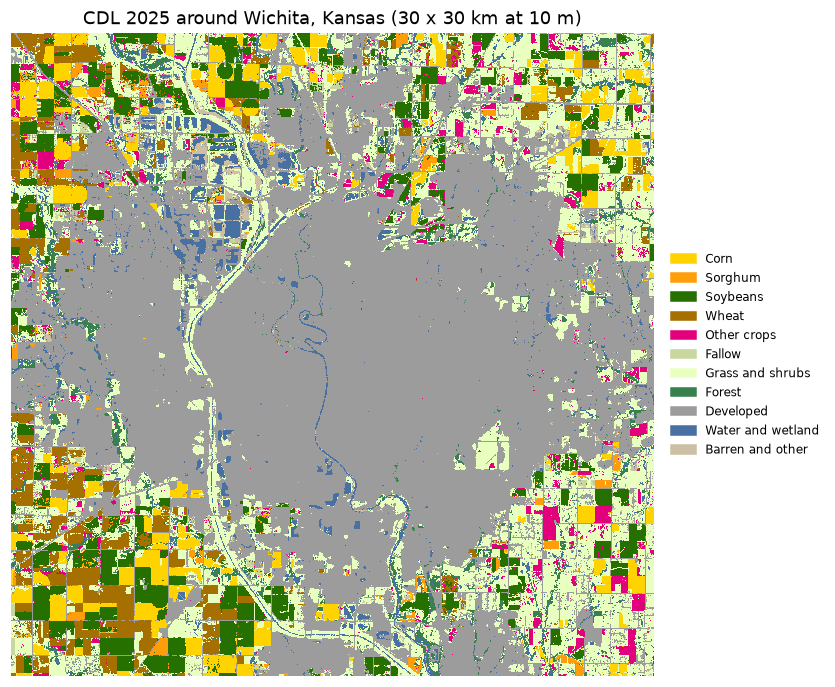

In [4]:
codes, counts = np.unique(win.values, return_counts=True)  # pixels per CDL code
top = pd.Series(counts, index=codes).sort_values(ascending=False).head(6)  # the six most common
names = {1: "Corn", 4: "Sorghum", 5: "Soybeans", 24: "Winter wheat", 61: "Fallow", 111: "Water", 121: "Developed, open",  # CDL legend
         122: "Developed, low", 123: "Developed, medium", 124: "Developed, high", 141: "Deciduous forest", 176: "Grass/pasture"}  # names
print((top / win.size * 100).round(1).rename(index=lambda c: f"{c} {names.get(c, '')}").to_string())  # shares in percent
fig, ax = plt.subplots(figsize=(8.5, 6.5))  # one map
dd.cdl_groups_plot(ax, win.values, extent=dd.extent(win))  # codes drawn as land cover groups
ax.set_title("CDL 2025 around Wichita, Kansas (30 x 30 km at 10 m)"); ax.set_axis_off(); plt.tight_layout(); plt.show()  # draw

Reading the window took a fraction of a second and a few megabytes, out of 152 GB. Laziness plus
a tiled, indexed file format is what makes a continental 10 m product usable on a laptop.
Notebook 03 goes further and processes every pixel of the CDL, chunk by chunk.

## GeoTIFF, COG and Zarr compared

The DEM is rewritten four ways: a **striped** GeoTIFF (`gdal_translate -co TILED=NO`), a tiled
DEFLATE GeoTIFF (`format="gtiff"`), a COG with overviews (`format="cog"`) and a Zstandard
compressed Zarr store (`format="zarr"`). Then each is read whole, and 200 random 256 x 256 windows
are read from each.

In [5]:
dem = pdist.read_raster(src, chunks={"y": 2048, "x": 2048})  # lazy DEM
paths = {"GeoTIFF tiled, uncompressed (original)": src}  # name -> path
paths["GeoTIFF striped"] = IO / "elev_striped.tif"  # rows, no tiles
subprocess.run(["gdal_translate", "-q", "-co", "TILED=NO", str(src), str(paths["GeoTIFF striped"])], check=True)  # write it
w = {}  # write times
with dd.timer("write tiled DEFLATE GeoTIFF", w):  # chunk by chunk
    paths["GeoTIFF tiled, DEFLATE"] = Path(pdist.write_raster(dem, IO / "elev_deflate.tif", format="gtiff"))  # write
with dd.timer("write COG", w):  # tiled, then converted with overviews
    paths["COG, DEFLATE"] = Path(pdist.write_raster(dem, IO / "elev_cog.tif", format="cog"))  # write
with dd.timer("write Zarr", w):  # chunks written in parallel
    paths["Zarr, Zstandard"] = Path(pdist.write_raster(dem.rename("elev"), IO / "elev.zarr"))  # write

write tiled DEFLATE GeoTIFF: 14.11 s


write COG: 17.92 s


write Zarr: 1.03 s


In [6]:
import rasterio  # direct windowed reads of GeoTIFFs
import zarr  # direct reads of Zarr chunks
from rasterio.windows import Window  # a rectangle of rows and columns

rng = np.random.default_rng(0)  # random windows
wins = [(int(r), int(c)) for r, c in zip(rng.integers(0, dem.shape[0] - 256, 200), rng.integers(0, dem.shape[1] - 256, 200))]  # corners


def open_any(p):  # lazy DataArray for any of the formats
    if p.suffix == ".zarr":  # Zarr store
        return pdist.read_zarr(p)["elev"]  # its variable
    return pdist.read_raster(p, chunks={"y": 2048, "x": 2048})  # GeoTIFF or COG


def read_windows(p):  # 200 windows read straight from the file, without Dask
    if p.suffix == ".zarr":  # Zarr: slicing reads only the chunks that overlap
        arr = zarr.open(str(p), mode="r")["elev"]  # the array
        for r, c in wins:  # each window
            arr[r:r + 256, c:c + 256]  # read it
    else:  # GeoTIFF or COG through GDAL
        with rasterio.open(p) as f:  # one open file handle
            for r, c in wins:  # each window
                f.read(1, window=Window(c, r, 256, 256))  # read it


rows = []  # one row per format
for name, p in paths.items():  # each format
    float(open_any(p).mean()); read_windows(p)  # warm the page cache
    t = time.perf_counter(); float(open_any(p).mean()); whole = time.perf_counter() - t  # read everything, in parallel
    t = time.perf_counter(); read_windows(p); windows = time.perf_counter() - t  # 200 small windows, one after another
    rows.append({"format": name, "size GB": round(folder_gb(p), 2), "read whole, 24 threads (s)": round(whole, 2),  # size and time
                 "200 windows of 256 x 256 (ms each)": round(windows / len(wins) * 1000, 2)})  # windowed reads
fmt = pd.DataFrame(rows).set_index("format")  # table
fmt  # show

,size GB,"read whole, 24 threads (s)",200 windows of 256 x 256 (ms each)
format,,,
"GeoTIFF tiled, uncompressed (original)",1.06,0.69,0.14
GeoTIFF striped,1.05,0.71,0.85
"GeoTIFF tiled, DEFLATE",0.12,0.71,0.69
"COG, DEFLATE",0.26,0.74,1.25
"Zarr, Zstandard",0.14,0.43,9.79


Compression shrank the DEM about eightfold (half the pixels are NaN and elevations vary
smoothly), yet whole-file reads were no slower, because 24 threads decompress in parallel. Small
windows tell the formats apart. The original tiled GeoTIFF read a 256 x 256 window in about a
tenth of a millisecond, touching only the few 128 x 128 blocks under it. The striped copy took
about six times longer, because every window reads 256 complete rows of 15,245 pixels. The
compressed tiled files pay for decompressing their blocks (the COG's larger 512 x 512 blocks
cost more per window). The Zarr store was slowest by far for windows: its chunks are 2048 x 2048,
so every small window decompresses a whole 16 MB chunk. The writes differ
too: GeoTIFF and COG were written chunk by chunk under a lock, Zarr's independent chunk files in
parallel. Zarr suits the intermediate results of a Dask pipeline (use chunks near the size of the
windows you will read); COG is the format to publish, since any HTTP client can read its windows
and overviews.

## A multi-layer Zarr cube

Several rasters on one grid fit naturally in one Zarr store, with one variable per layer. "On
one grid" has to be checked, though. The 15 Great Plains files have the same resolution but not
the same origin or size:

In [7]:
grids = []  # one row per file
for f in sorted(dd.GP_RASTERS.glob("*.tif")):  # every covariate file
    with rasterio.open(f) as r:  # header only
        grids.append({"file": f.stem, "rows": r.height, "cols": r.width, "x origin": r.transform.c, "y origin": r.transform.f})  # grid
grids = pd.DataFrame(grids).set_index("file")  # table
ref = grids.loc["elev"]  # the reference grid
grids["dx to elev (m)"] = (grids["x origin"] - ref["x origin"]).round(1)  # origin offsets
grids["dy to elev (m)"] = (grids["y origin"] - ref["y origin"]).round(1)  # origin offsets
grids.groupby(["rows", "cols", "dx to elev (m)", "dy to elev (m)"]).apply(lambda g: ", ".join(g.index), include_groups=False).rename("files").reset_index()  # distinct grids

,rows,cols,dx to elev (m),dy to elev (m),files
0,17194,15245,14.2,-138.1,frg
1,17195,15246,14.9,-35.5,"kfactor, silt_clay"
2,17196,15245,0.0,0.0,"aspect, elev, h_curvature, slope, slopeleng, t..."
3,17196,15246,-5.8,-38.1,"nlcd, preci, temp"
4,17196,15246,10.1,-38.1,ndvi


Five different grids: most origins differ from the elevation grid by 6 to 38 m (less than half
a 90 m pixel), the forest fragmentation layer by 138 m (one and a half pixels), and some files have
an extra row or column. The files were clearly meant to share the elevation grid, but xarray
aligns layers by their coordinate labels, and with these offsets no labels match: an expression such as `ndvi * preci` would silently return an empty array or a
doubled, mostly NaN grid. The chapter helper `dd.gp_raster` therefore snaps every layer to the
elevation grid by nearest pixel (a whole-pixel slice plus NaN padding, still lazy). Check the
grids of any raster stack before combining layers.

In [8]:
layers = ["ndvi", "preci", "temp", "silt_clay"]  # four covariates on three different grids
cube = xr.Dataset({n: dd.gp_raster(n, chunks={"y": 2048, "x": 2048}) for n in layers})  # lazy Dataset, snapped to one grid
for n in layers:  # drop per-file attributes that would clash
    cube[n].attrs = {}  # keep the store tidy
print("cube grid equals the DEM grid:", cube.sizes == dict(zip(("y", "x"), dem.shape)))  # one grid now
with dd.timer("write 4 layers (4.2 GB of float32) to Zarr"):  # in parallel
    pdist.write_raster(cube, IO / "gp_cube.zarr")  # one store, four arrays
zc = pdist.read_zarr(IO / "gp_cube.zarr")  # lazy again
print(zc)  # its contents
print(f"on disk {folder_gb(IO / 'gp_cube.zarr'):.2f} GB in {sum(1 for _ in (IO / 'gp_cube.zarr').rglob('*') if _.is_file())} files")  # size and objects

cube grid equals the DEM grid: True


write 4 layers (4.2 GB of float32) to Zarr: 3.52 s
<xarray.Dataset> Size: 4GB
Dimensions:      (y: 17196, x: 15245)
Coordinates:
  * y            (y) float64 138kB 2.539e+06 2.539e+06 ... 9.92e+05 9.919e+05
  * x            (x) float64 122kB -1.25e+06 -1.25e+06 ... 1.216e+05 1.217e+05
Data variables:
    ndvi         (y, x) float32 1GB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    preci        (y, x) float32 1GB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    silt_clay    (y, x) float32 1GB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
    spatial_ref  int64 8B ...
    temp         (y, x) float32 1GB dask.array<chunksize=(2048, 2048), meta=np.ndarray>
on disk 0.13 GB in 275 files


In [9]:
with dd.timer("mean of every layer from the Zarr cube"):  # one parallel pass
    print({k: round(float(v), 2) for k, v in zc.mean().items()})  # four means
with dd.timer("the same from the four GeoTIFFs"):  # four files
    print({n: round(float(dd.gp_raster(n).mean()), 2) for n in layers})  # four means

{'ndvi': 0.4, 'preci': 483.84, 'silt_clay': 53.9, 'spatial_ref': 0.0, 'temp': 9.19}
mean of every layer from the Zarr cube: 1.59 s


{'ndvi': 0.4, 'preci': 483.84, 'temp': 9.19, 'silt_clay': 53.9}
the same from the four GeoTIFFs: 2.94 s


## A lazy Sentinel-2 cube from STAC

`pdist.read_stac` loads STAC items lazily with `odc-stac`. The search below finds Sentinel-2
scenes over Wichita with little cloud in summer 2025; the cube is built from the catalogue
metadata alone, and only the pixels needed for the median NDVI are downloaded.

In [10]:
import planetary_computer as pc  # signs Planetary Computer URLs
import pystac_client  # STAC search

cat = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1", modifier=pc.sign_inplace)  # catalogue
bbox = (-97.50, 37.60, -97.20, 37.80)  # Wichita, lon/lat
items = cat.search(collections=["sentinel-2-l2a"], bbox=bbox, datetime="2025-06-01/2025-08-31",  # summer 2025
                   query={"eo:cloud_cover": {"lt": 10}}).item_collection()  # nearly clear scenes
s2 = pdist.read_stac(items, ["B04", "B08", "SCL"], resolution=20, crs="EPSG:32614", bbox=bbox,  # lazy cube at 20 m
                     chunks={"x": 1024, "y": 1024}, groupby="solar_day")  # one layer per day
print(len(items), "items |", dict(s2.sizes), "| lazy:", pdist.is_lazy(s2.B04), f"| {dd.gb(s2.nbytes)} if loaded")  # nothing read yet

13 items | {'y': 1134, 'x': 1343, 'time': 12} | lazy: True | 0.22 GB if loaded


download the needed chunks and compute the median NDVI: 5.13 s


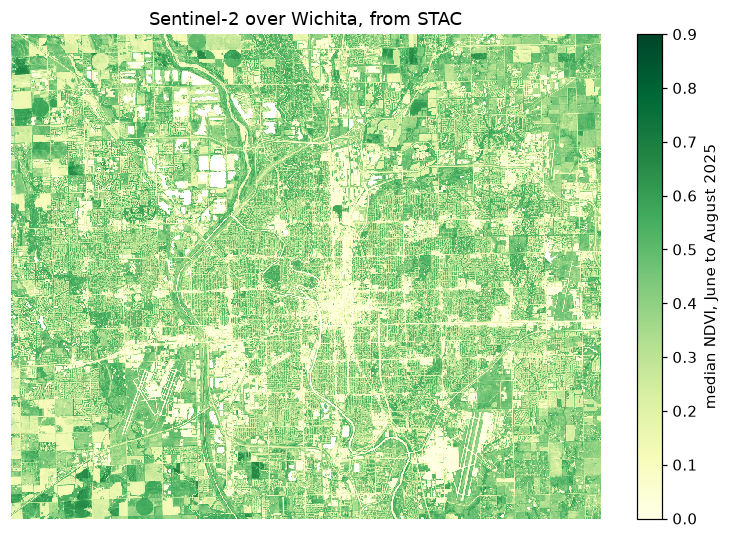

In [11]:
clear = s2.SCL.isin([4, 5])  # vegetation and bare soil classes of the scene classification
ndvi = ((s2.B08.astype("float32") - s2.B04) / (s2.B08.astype("float32") + s2.B04)).where(clear)  # NDVI of clear pixels
with dd.timer("download the needed chunks and compute the median NDVI"):  # reads happen here
    med = ndvi.median("time").compute()  # median over the summer
fig, ax = plt.subplots(figsize=(7, 5))  # one map
im = med.plot.imshow(ax=ax, cmap="YlGn", vmin=0, vmax=0.9, add_colorbar=False)  # map
plt.colorbar(im, ax=ax, label="median NDVI, June to August 2025"); ax.set_title("Sentinel-2 over Wichita, from STAC"); ax.set_axis_off()  # labels
plt.tight_layout(); plt.show()  # draw

## Partitioned GeoParquet

The Kansas buildings were written by `pdist.write_vector` as 24 Hilbert-sorted GeoParquet files,
each with a `bbox` covering column. `pdist.read_vector` reads a folder with one task per file;
with `bbox=` each file's statistics decide whether it is opened at all.

In [12]:
files = sorted(dd.BUILDINGS.glob("*.parquet"))  # the partition files
print(len(files), "files,", f"{folder_gb(dd.BUILDINGS):.2f} GB")  # dataset size
t = {}  # timings
with dd.timer("read all 24 files in parallel", t):  # one task per file
    bld = pdist.read_vector(dd.BUILDINGS)  # GeoDataFrame
with dask.config.set(scheduler="synchronous"):  # one file at a time
    with dd.timer("read all 24 files one after another", t):  # for comparison
        pdist.read_vector(dd.BUILDINGS)  # same result
with dd.timer("read only buildings in a Wichita bounding box", t):  # filtered read
    wich = pdist.read_vector(dd.BUILDINGS, bbox=bbox)  # row groups outside the box are skipped
print(f"{len(bld):,} buildings in all; {len(wich):,} in the Wichita box")  # sizes

24 files, 0.19 GB


read all 24 files in parallel: 2.28 s


read all 24 files one after another: 2.07 s


read only buildings in a Wichita bounding box: 0.88 s
1,605,334 buildings in all; 159,731 in the Wichita box


Reading the 24 files on 24 threads was no faster than reading them one after another. Most of
the time goes into turning the stored WKB bytes into Shapely geometry objects, and that step
holds the GIL, so the threads take turns. (Worker processes would decode in parallel, but then
pay to send 1.6 million geometries back to this process.) What does help is reading less: the
bounding-box read decoded only the buildings near Wichita and was faster. To see why the Hilbert order
matters, the next cell writes the same buildings in two ways (Hilbert-sorted and in random order)
and repeats the bounding-box query on both.

In [13]:
shuffled = bld.sample(frac=1, random_state=0)  # rows in random order
pdist.write_vector(bld, IO / "bld_hilbert", npartitions=48)  # 48 Hilbert-sorted files
pdist.write_vector(shuffled, IO / "bld_random", npartitions=48, spatial=False)  # 48 files in random order
import pyarrow.parquet as pq  # Parquet metadata
for name in ["bld_hilbert", "bld_random"]:  # both layouts
    fs = sorted((IO / name).glob("*.parquet"))  # its files
    hit = 0  # files whose bbox statistics overlap the query box
    for f in fs:  # each file
        st = pq.ParquetFile(f).metadata.row_group(0)  # first row group statistics
        cols = {st.column(i).path_in_schema: st.column(i).statistics for i in range(st.num_columns)}  # by column
        x0, y0 = cols["bbox.xmin"].min, cols["bbox.ymin"].min  # lower left of the file
        x1, y1 = cols["bbox.xmax"].max, cols["bbox.ymax"].max  # upper right
        hit += not (x1 < bbox[0] or x0 > bbox[2] or y1 < bbox[1] or y0 > bbox[3])  # overlaps the query?
    t0 = time.perf_counter(); n = len(pdist.read_vector(IO / name, bbox=bbox)); s = time.perf_counter() - t0  # the query
    print(f"{name:12s} files read for the Wichita box: {hit:2d} of {len(fs)} | {n:,} buildings in {s:.2f} s")  # result

bld_hilbert  files read for the Wichita box: 10 of 48 | 159,731 buildings in 1.74 s


bld_random   files read for the Wichita box: 48 of 48 | 159,731 buildings in 1.64 s


Both layouts return the same buildings. In random order every file spans the whole state, so all
48 files must be opened and filtered; Hilbert-sorted, only 10 files overlap Wichita. Locally both
queries took the same time, because the files sit in the page cache and decoding the 160,000
matching geometries dominates. On object storage (S3, Azure Blob) every file is a separate
download, and reading 10 files instead of 48 is what makes a query fast.

## GeoParquet, Shapefile and GeoPackage

The same 400,000 buildings in three formats. For OGR formats `pdist.read_vector` splits the file
into row ranges and reads them in parallel with `pyogrio`.

In [14]:
sub = bld.iloc[:400_000].reset_index(drop=True)  # 400,000 buildings
sub.to_parquet(IO / "b400k.parquet")  # GeoParquet
sub.to_file(IO / "b400k.shp", engine="pyogrio")  # Shapefile
sub.to_file(IO / "b400k.gpkg", engine="pyogrio")  # GeoPackage
rows = []  # timings
for name, p in [("GeoParquet", IO / "b400k.parquet"), ("Shapefile", IO / "b400k.shp"), ("GeoPackage", IO / "b400k.gpkg")]:  # formats
    gpd.read_file(p) if p.suffix != ".parquet" else gpd.read_parquet(p)  # warm the cache
    t0 = time.perf_counter(); gpd.read_parquet(p) if p.suffix == ".parquet" else gpd.read_file(p, engine="pyogrio"); one = time.perf_counter() - t0  # plain GeoPandas
    t0 = time.perf_counter(); g = pdist.read_vector(p, npartitions=8); par = time.perf_counter() - t0  # GeoLattice, parallel where possible
    rows.append({"format": name, "size MB": round(folder_gb(p) * 1000 if p.suffix != ".shp" else sum(f.stat().st_size for f in IO.glob("b400k.*") if f.suffix in (".shp", ".shx", ".dbf", ".prj")) / 1e6, 1),  # size
                 "GeoPandas (s)": round(one, 2), "pdist.read_vector (s)": round(par, 2), "rows": len(g)})  # times
pd.DataFrame(rows).set_index("format")  # table

,size MB,GeoPandas (s),pdist.read_vector (s),rows
format,,,,
GeoParquet,31.8,0.27,0.42,400000
Shapefile,71.8,0.48,0.75,400000
GeoPackage,93.1,0.60,0.73,400000


With plain GeoPandas, GeoParquet read 400,000 buildings fastest, in about a quarter of a second,
ahead of the Shapefile and the GeoPackage. Splitting the files into row ranges with
`pdist.read_vector` made every format slower here, for the same reason as above: building Shapely
objects holds the GIL, so parallel tasks only add overhead. (These sub-second timings vary from run
to run.) GeoParquet's other advantages matter as much: it is less than half the size of the
others, readers can take only the columns they need, and it can be partitioned and filtered by
bounding box. Convert large vector data to GeoParquet once, and partition it.

## 38 million taxi trips as a lazy table

Not every big table has geometries. The 2023 NYC yellow taxi trips (38.3 million rows) are one
Parquet file with 37 row groups; read with Dask, each row group is a partition, and grouped
counts run in parallel without loading the file into one DataFrame. Notebook 04 joins them to
the taxi zones.

In [15]:
trips = dd.taxi_trips(columns=["PULocationID", "DOLocationID", "trip_distance", "total_amount"])  # lazy Dask DataFrame
print(trips.npartitions, "partitions | lazy:", pdist.is_lazy(trips))  # one per row group
with dd.timer("count trips and mean fare by pickup zone (38 million rows)"):  # grouped reduction
    by_zone = trips.groupby("PULocationID").agg({"trip_distance": "count", "total_amount": "mean"}).compute()  # small result
by_zone.columns = ["trips", "mean_fare"]  # readable names
print(f"{int(by_zone.trips.sum()):,} trips over {len(by_zone)} pickup zones")  # totals
by_zone.sort_values("trips", ascending=False).head(5).round(2)  # busiest zones

37 partitions | lazy: True


count trips and mean fare by pickup zone (38 million rows): 0.39 s
38,310,226 trips over 263 pickup zones


,trips,mean_fare
PULocationID,,
132,1992304,78.07
237,1791795,20.44
161,1766041,24.95
236,1596584,21.08
162,1353753,24.18


In [16]:
shutil.rmtree(IO)  # remove the scratch files written above
print("removed", IO)  # done

removed outputs/io


## Summary and exercises

- Lazy readers open the header only; a window of the 152 billion pixel CDL was read in a fraction
  of a second because only its blocks were decoded.
- Chunks should be multiples of the file's blocks. Here GDAL's block cache hid the cost of
  misaligned chunks; with worker processes or object storage it does not.
- The 15 Great Plains rasters lie on four slightly different grids; layers must be snapped to one
  grid before they are combined.
- Striped GeoTIFFs suit whole-file reads, tiled GeoTIFFs and COGs suit windows, and Zarr suits
  parallel writes and reads of intermediate results and multi-layer cubes.
- `pdist.read_stac` builds a lazy cube from catalogue metadata and downloads only what a
  computation needs.
- Partitioned, Hilbert-sorted GeoParquet with a `bbox` column lets bounding-box queries skip most
  files. Decoding geometries holds the GIL, so reading fewer of them beats reading them on more
  threads. GeoParquet was the smallest format and the fastest to read.
- A Parquet table of 38 million rows is a lazy Dask DataFrame with one partition per row group.

**Exercises**

1. Write the DEM to Zarr with 512, 2048 and 8192 pixel chunks. How do the number of files, the
   write time and the time to read 200 random windows change?
2. Read the CDL window around Wichita with `chunks={"y": 576, "x": 512}` (the file's blocks) and
   with `{"y": 600, "x": 600}`. Compare the times.
3. Repeat the Sentinel-2 search for winter 2024-25 and map the difference in median NDVI.
4. Write the buildings with `partition_on` set to a column of your choice (for example a size
   class from `pdist.vector.area`) and inspect the folder structure that results.